<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Exercise 03: ANOVA Table, $R^2$, Prediction and Residuals

Lecture 3 looked at simple linear regression from the point of view of **analysis of variance** (ANOVA; analýza rozptylu): how much of the variability of $y_1, \dots, y_n$ is explained by the regression line. It introduced the decomposition $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$, the **coefficient of determination** $R^2$ (koeficient determinace), the $F$-test of $H_0: \beta_1 = 0$ with $F = T_1^2$, the **ANOVA table** (tabulka ANOVA), and warned that a large $R^2$ is neither proof of a good model nor of a causal relationship.

Lecture 4 added the **regression through the origin** (regresní model procházející počátkem), the two kinds of **prediction**, a confidence interval for the mean response $\mu_0 = \mathrm{E}\,Y_0$ and a **prediction interval** (interval predikce) for a new observation $Y_0$, and the first tools for **checking model adequacy** (ověření adekvátnosti modelu): properties of the residuals, studentized residuals and residual plots.

We start with the individual work left over from Exercise 02, then go through Lecture 3 on the `mpg` data and the speed-of-sound example, and Lecture 4 on the birth weight and Clark County examples from the slides. R equivalents are mentioned in brackets.

## Learning goals
- Compute $\mathrm{SST}$, $\mathrm{SSR}$, $\mathrm{SSE}$, $R^2$ and $F$ by hand, build the ANOVA table and read it from `statsmodels` (`anova_lm`, the `R-squared` and `F-statistic` rows of `summary()`).
- Verify $R^2 = \rho^2(\mathbf{x}, \mathbf{y})$ and $F = (n-2)R^2/(1-R^2) = \mathrm{SSR}/s_n^2 = T_1^2$, and check the $\chi^2$ and $F$ distributions of Theorem 2.5 by simulation.
- Understand why $R^2$ depends on the spread of $x$ and on $\beta_1$, why a significant model can have a small $R^2$, and why correlation is not causation.
- Fit a model through the origin, build its ANOVA table and explain why its $R^2$ cannot be compared with the $R^2$ of a model with intercept.
- Compute the confidence interval for $\mathrm{E}\,Y_0$ and the prediction interval for $Y_0$ by hand and with `get_prediction`, and explain why the prediction interval is wider.
- Compute studentized residuals and read the basic residual plots.

Theorem and remark numbers refer to the lecture slides `lectures/01RAD_2024.pdf` (Lecture 3 on pp. 27–39, Lecture 4 on pp. 40–64).

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
rng = np.random.default_rng(2026)

In [2]:
url_mpg = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/mpg.csv'
try:
    mpg_raw = pd.read_csv(url_mpg)
except Exception:
    mpg_raw = sns.load_dataset('mpg')          # the same data set ships with seaborn
cars = mpg_raw.dropna().reset_index(drop=True)
print(f'{cars.shape[0]} cars')

model = smf.ols('mpg ~ weight', data=cars).fit()      # R: mod <- lm(mpg ~ weight, data = cars)

x = cars['weight'].to_numpy(dtype=float)
y = cars['mpg'].to_numpy(dtype=float)
n = len(x)
x_bar, y_bar = x.mean(), y.mean()
S_xx = np.sum((x - x_bar) ** 2)
beta1_hat = np.sum((x - x_bar) * y) / S_xx
beta0_hat = y_bar - beta1_hat * x_bar
y_hat = beta0_hat + beta1_hat * x
e_hat = y - y_hat
s_n2 = np.sum(e_hat ** 2) / (n - 2)
s_n = np.sqrt(s_n2)
se_beta1 = s_n / np.sqrt(S_xx)
print(f'beta0_hat = {beta0_hat:.4f}, beta1_hat = {beta1_hat:.6f}, s_n = {s_n:.4f}')

392 cars
beta0_hat = 46.2165, beta1_hat = -0.007647, s_n = 4.3327


## 2. Solution of the individual work from Exercise 02
The task: model fuel consumption in litres per 100 km by engine power in kW, $\text{L/100km} = 235.215/\text{mpg}$, $\text{kW} = 0.7457 \cdot \text{hp}$, and answer seven questions with the tools of Lecture 2.

In [3]:
# step 1: new variables
cars['l_per_100km'] = 235.215 / cars['mpg']
cars['kw'] = 0.7457 * cars['horsepower']
cars[['l_per_100km', 'kw']].describe().T

,count,mean,std,min,25%,50%,75%,max
l_per_100km,392.0,11.2486,3.9138,5.0475,8.1109,10.3404,13.8362,26.135
kw,392.0,77.9028,28.7029,34.3022,55.9275,69.7229,93.9582,171.511


,manual,statsmodels
beta0_hat,2.1682,2.1682
beta1_hat,0.1166,0.1166
s_n,2.0337,2.0337
SE(beta0_hat),0.2974,0.2974
SE(beta1_hat),0.0036,0.0036


Each additional 10 kW costs on average 1.17 L/100 km.


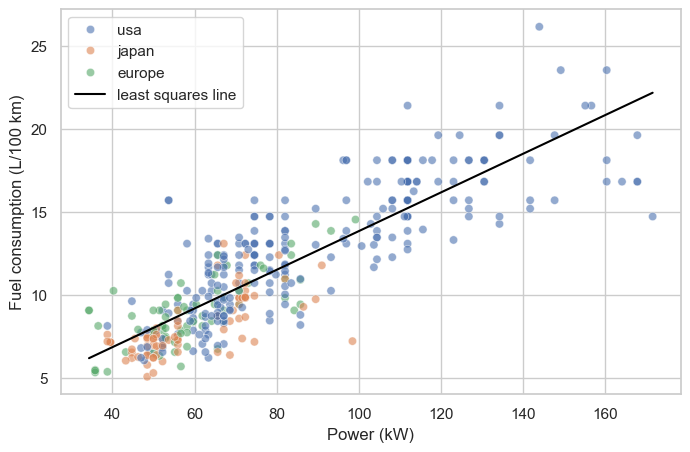

In [4]:
# steps 2 and 3: fit, plot, recompute by hand
fuel = smf.ols('l_per_100km ~ kw', data=cars).fit()       # R: lm(l_per_100km ~ kw, data = cars)

xk = cars['kw'].to_numpy(dtype=float)
yk = cars['l_per_100km'].to_numpy(dtype=float)
nk = len(xk)
S_xx_k = np.sum((xk - xk.mean()) ** 2)
b1_k = np.sum((xk - xk.mean()) * yk) / S_xx_k
b0_k = yk.mean() - b1_k * xk.mean()
s_k = np.sqrt(np.sum((yk - b0_k - b1_k * xk) ** 2) / (nk - 2))
se0_k = s_k * np.sqrt(1 / nk + xk.mean() ** 2 / S_xx_k)
se1_k = s_k / np.sqrt(S_xx_k)

display(pd.DataFrame({
    'manual': [b0_k, b1_k, s_k, se0_k, se1_k],
    'statsmodels': [fuel.params['Intercept'], fuel.params['kw'], np.sqrt(fuel.scale),
                    fuel.bse['Intercept'], fuel.bse['kw']]},
    index=['beta0_hat', 'beta1_hat', 's_n', 'SE(beta0_hat)', 'SE(beta1_hat)']))
print(f'Each additional 10 kW costs on average {10 * b1_k:.2f} L/100 km.')

plt.figure(figsize=(8, 5))
sns.scatterplot(data=cars, x='kw', y='l_per_100km', hue='origin', alpha=0.6)
grid_k = np.linspace(xk.min(), xk.max(), 100)
plt.plot(grid_k, b0_k + b1_k * grid_k, color='black', label='least squares line')
plt.xlabel('Power (kW)')
plt.ylabel('Fuel consumption (L/100 km)')
plt.legend()
plt.show()

In [5]:
# steps 4 to 7: intervals and tests
t975, t995 = stats.t.ppf([0.975, 0.995], df=nk - 2)
ci95 = (b1_k - t975 * se1_k, b1_k + t975 * se1_k)
ci99 = (b1_k - t995 * se1_k, b1_k + t995 * se1_k)
print(f'95% CI for beta1: ({ci95[0]:.4f}, {ci95[1]:.4f})   conf_int: {fuel.conf_int().loc["kw"].round(4).tolist()}')
for b in (0.10, 0.12):
    T = (b1_k - b) / se1_k
    p = 2 * stats.t.sf(abs(T), df=nk - 2)
    inside = ci95[0] < b < ci95[1]
    print(f'H0: beta1 = {b:.2f}:  T = {T:6.2f}, p = {p:.2e}, b inside the 95% CI: {inside}')

T0 = b0_k / se0_k
print(f'\nH0: beta0 = 0:  beta0_hat = {b0_k:.3f}, T0 = {T0:.2f}, p = {2 * stats.t.sf(abs(T0), nk - 2):.1e}')
print(f'smallest power in the data: {xk.min():.1f} kW')

print(f'\n99% CI for beta1: ({ci99[0]:.4f}, {ci99[1]:.4f}), width ratio 99%/95% = {t995 / t975:.3f} = t_0.995/t_0.975')

europe = smf.ols('l_per_100km ~ kw', data=cars[cars['origin'] == 'europe']).fit()
print(f'\nEurope (n = {int(europe.nobs)}): beta1_hat = {europe.params["kw"]:.4f}, '
      f'95% CI {europe.conf_int().loc["kw"].round(4).tolist()}')

95% CI for beta1: (0.1095, 0.1236)   conf_int: [0.1095, 0.1236]
H0: beta1 = 0.10:  T =   4.62, p = 5.19e-06, b inside the 95% CI: False
H0: beta1 = 0.12:  T =  -0.96, p = 3.38e-01, b inside the 95% CI: True

H0: beta0 = 0:  beta0_hat = 2.168, T0 = 7.29, p = 1.7e-12
smallest power in the data: 34.3 kW

99% CI for beta1: (0.1073, 0.1258), width ratio 99%/95% = 1.317 = t_0.995/t_0.975

Europe (n = 68): beta1_hat = 0.1027, 95% CI [0.0797, 0.1258]


**Conclusions.**
1. Consumption ranges from about 5 to 25 L/100 km, power from about 34 to 172 kW.
2. $\widehat{\beta}_1 \approx 0.117$: every 10 kW of extra power costs on average about 1.2 L/100 km. The scatter plot is roughly linear, which is not the case for `mpg` against `horsepower`: the reciprocal scale L/100 km straightens the relationship.
3. The manual values agree with `statsmodels` to all printed digits.
4. The 95 % interval for $\beta_1$ is about $(0.110, 0.124)$. The value $0.10$ lies outside and the test rejects it ($T \approx 4.6$); the value $0.12$ lies inside and the test does not reject it ($|T| \approx 1$, $p \approx 0.34$). Interval and test always agree: the test at level $\alpha$ rejects exactly the values outside the $100(1-\alpha)$ % interval.
5. $H_0: \beta_0 = 0$ is rejected ($T_0 \approx 7$). A model through the origin would claim that a car with zero power consumes nothing; the weakest car in the data has about 34 kW, so the intercept is an extrapolation far outside the data. Lecture 4 (Remark 2.15) made the point: whether $\beta_0 = 0$ is reasonable is a question about linearity near zero and about the subject matter, the test only tells us whether the data contradict it within the observed range.
6. The 99 % interval is wider by the factor $t_{0.995}(n-2)/t_{0.975}(n-2) \approx 1.32$: higher confidence costs width.
7. For the 68 European cars the interval is roughly $(0.08, 0.13)$; it contains the estimate for all cars, so the data do not show a different slope for European cars. Overlapping intervals are only an informal check; the proper test compares the slopes within one model with an interaction term, later in the course.

## 3. Decomposition of variability: $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$
Back to fuel efficiency on weight. Lecture 3 measured the variability of the data by the **total sum of squares** (celkový součet čtverců) and split it into the **regression sum of squares** (regresní součet čtverců) and the **residual sum of squares** (reziduální součet čtverců):

$$\underbrace{\sum_{i=1}^n (y_i - \overline{y})^2}_{\mathrm{SST}} = \underbrace{\sum_{i=1}^n (\widehat{y}_i - \overline{y})^2}_{\mathrm{SSR}} + \underbrace{\sum_{i=1}^n (y_i - \widehat{y}_i)^2}_{\mathrm{SSE}}.$$

The proof rests on Lemma 2.1: for the least squares fit with intercept, (1) $\sum_i \widehat{e}_i = 0$, (2) the mean of the fitted values equals $\overline{y}$, (3) $\sum_i \widehat{e}_i\, \widehat{y}_i = 0$. We check all three numerically and then the decomposition itself.

In [6]:
SST = np.sum((y - y_bar) ** 2)
SSR = np.sum((y_hat - y_bar) ** 2)
SSE = np.sum(e_hat ** 2)

print('Lemma 2.1')
print(f'  (1) sum of residuals             : {e_hat.sum(): .2e}')
print(f'  (2) mean of fitted values - y_bar : {y_hat.mean() - y_bar: .2e}')
print(f'  (3) sum of residuals * fitted     : {np.sum(e_hat * y_hat): .2e}')
print(f'\nSST = {SST:.2f}')
print(f'SSR = {SSR:.2f}')
print(f'SSE = {SSE:.2f}')
print(f'SSR + SSE - SST = {SSR + SSE - SST:.2e}')
print(f'SSR = beta1_hat^2 * S_xx: {beta1_hat ** 2 * S_xx:.2f}')

Lemma 2.1
  (1) sum of residuals             :  1.59e-12
  (2) mean of fitted values - y_bar :  0.00e+00
  (3) sum of residuals * fitted     :  3.27e-11

SST = 23818.99
SSR = 16497.76
SSE = 7321.23
SSR + SSE - SST = 0.00e+00
SSR = beta1_hat^2 * S_xx: 16497.76


The picture shows the three kinds of deviation for a few cars: the total deviation $y_i - \overline{y}$ (left) is the sum of the part explained by the line, $\widehat{y}_i - \overline{y}$ (middle), and the residual $y_i - \widehat{y}_i$ (right). The squares of the vertical segments add up to $\mathrm{SST}$, $\mathrm{SSR}$ and $\mathrm{SSE}$. For the squares to add up, the cross term $2\sum_i (\widehat{y}_i - \overline{y})\,\widehat{e}_i$ must vanish; that is what the lemma guarantees.

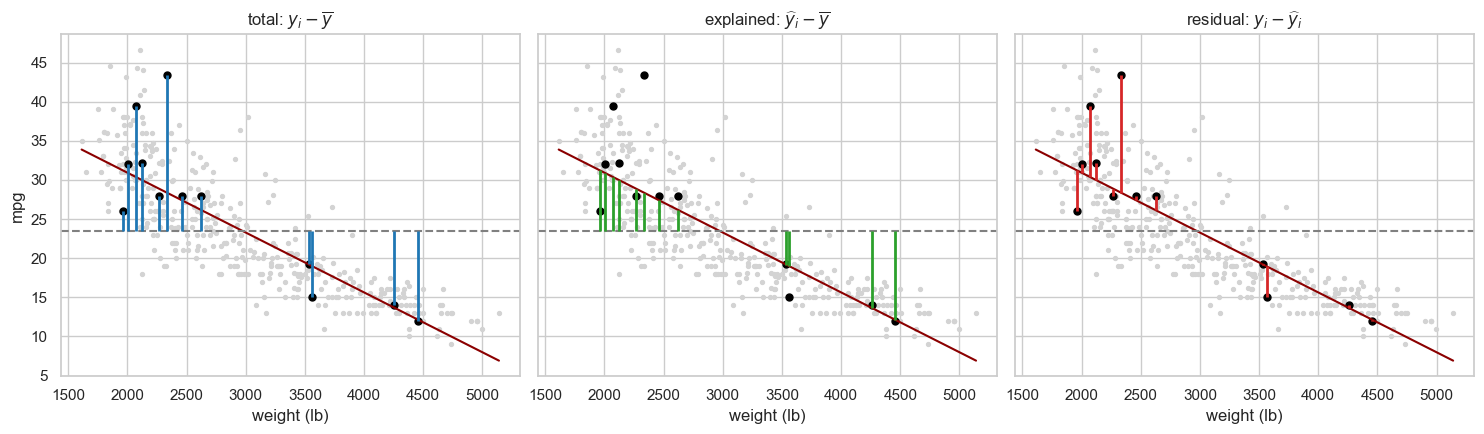

In [7]:
idx = rng.choice(n, size=12, replace=False)
grid = np.linspace(x.min(), x.max(), 100)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
segments = [(y_bar, y, 'total: $y_i - \\overline{y}$', 'tab:blue'),
            (y_bar, y_hat, 'explained: $\\widehat{y}_i - \\overline{y}$', 'tab:green'),
            (y_hat, y, 'residual: $y_i - \\widehat{y}_i$', 'tab:red')]
for ax, (start, end, title, col) in zip(axes, segments):
    ax.scatter(x, y, s=8, color='lightgray')
    ax.scatter(x[idx], y[idx], s=25, color='black')
    ax.plot(grid, beta0_hat + beta1_hat * grid, color='darkred')
    ax.axhline(y_bar, color='gray', ls='--')
    start_v = np.broadcast_to(start, y.shape)
    ax.vlines(x[idx], start_v[idx], end[idx], color=col, lw=2)
    ax.set_title(title)
    ax.set_xlabel('weight (lb)')
axes[0].set_ylabel('mpg')
plt.tight_layout()
plt.show()

**Exercise on the board.** In model $(\ast)$, $Y_i = \beta_0 + \beta_1 x_i + e_i$, the least squares estimates $\widehat{\beta}_0, \widehat{\beta}_1$ minimise
$$S(\beta_0, \beta_1) = \sum_{i=1}^n (y_i - \beta_0 - \beta_1 x_i)^2 .$$
Denote the fitted values $\widehat{y}_i = \widehat{\beta}_0 + \widehat{\beta}_1 x_i$ and the residuals $\widehat{e}_i = y_i - \widehat{y}_i$.

1. Set the partial derivatives $\partial S/\partial \beta_0$ and $\partial S/\partial \beta_1$ equal to zero at $(\widehat{\beta}_0, \widehat{\beta}_1)$ and write the two **normal equations** (normální rovnice) in terms of the residuals:
$$\text{(N1)}\quad \sum_{i=1}^n \widehat{e}_i = 0, \qquad\qquad \text{(N2)}\quad \sum_{i=1}^n x_i\, \widehat{e}_i = 0 .$$
2. Using only (N1) and (N2), i.e. **without** the explicit formulas for $\widehat{\beta}_0$ and $\widehat{\beta}_1$, prove all three points of Lemma 2.1:
$$\text{1)}\ \sum_i \widehat{e}_i = 0, \qquad \text{2)}\ \overline{\widehat{y}} = \frac{1}{n}\sum_i \widehat{y}_i = \overline{y}, \qquad \text{3)}\ \sum_i \widehat{e}_i\, \widehat{y}_i = 0 .$$
3. Start from the identity $y_i - \overline{y} = (\widehat{y}_i - \overline{y}) + (y_i - \widehat{y}_i)$, square it and sum over $i$. Show that the cross term $2\sum_i (\widehat{y}_i - \overline{y})(y_i - \widehat{y}_i)$ is zero and conclude $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$.
4. In the model through the origin, $Y_i = \beta_1 x_i + e_i$ (Section 10), only one normal equation remains. Which one? Which of the steps above fail, and which decomposition of $\sum_i y_i^2$ still holds?

<!--
Solution.
1. dS/db0 = -2 sum (y_i - b0 - b1 x_i) = 0 gives (N1); dS/db1 = -2 sum x_i (y_i - b0 - b1 x_i) = 0 gives (N2).
2. Point 1) is (N1). Point 2): sum yhat_i = sum y_i - sum e_i = sum y_i, divide by n.
   Point 3): sum e_i yhat_i = sum e_i (b0 + b1 x_i) = b0 sum e_i + b1 sum x_i e_i = 0 + 0.
3. Squaring and summing: SST = SSR + SSE + 2 sum (yhat_i - ybar) e_i,
   and sum (yhat_i - ybar) e_i = sum yhat_i e_i - ybar sum e_i = 0 - 0 = 0.
4. Only (N2) remains (derivative with respect to b1). (N1) and therefore points 1), 2) and the decomposition around ybar may fail.
   Point 3) still holds: sum e_i yhat_i = b1 sum x_i e_i = 0. Squaring y_i = yhat_i + e_i gives sum y_i^2 = sum yhat_i^2 + sum e_i^2 (Theorem 2.6).
-->

## 4. Coefficient of determination $R^2$
The share of the variability explained by the regression is

$$R^2 = \frac{\mathrm{SSR}}{\mathrm{SST}} = 1 - \frac{\mathrm{SSE}}{\mathrm{SST}}.$$

Theorem 2.4 adds $0 \le R^2 \le 1$, $R^2 = 1$ exactly when all points lie on a line, and $R^2 = \rho^2(\mathbf{x}, \mathbf{y})$, the squared sample correlation coefficient of $x$ and $y$. Since $\widehat{y}_i$ is a linear function of $x_i$, also $R^2 = \rho^2(\mathbf{y}, \widehat{\mathbf{y}})$; this form will matter for the model through the origin and later for multiple regression.

In [8]:
R2 = SSR / SST
pd.Series({
    'SSR / SST': R2,
    '1 - SSE / SST': 1 - SSE / SST,
    'rho^2(x, y)': np.corrcoef(x, y)[0, 1] ** 2,
    'rho^2(y, y_hat)': np.corrcoef(y, y_hat)[0, 1] ** 2,
    'statsmodels rsquared': model.rsquared,          # R: summary(mod)$r.squared
}, name='R^2').to_frame()

,R^2
SSR / SST,0.6926
1 - SSE / SST,0.6926
"rho^2(x, y)",0.6926
"rho^2(y, y_hat)",0.6926
statsmodels rsquared,0.6926


Weight alone explains about 69 % of the variability of fuel efficiency among the 392 cars; the remaining 31 % is left to other properties of the cars and to random variation.

## 5. The $F$-test and the ANOVA table
Any monotone function of $R^2$ gives an equivalent test of $H_0: \beta_1 = 0$. Lecture 3 used

$$F = \frac{(n-2)R^2}{1 - R^2} = \frac{\mathrm{SSR}}{s_n^2} = T_1^2,$$

and for i.i.d. $N(0, \sigma^2)$ errors $F \sim F(1, n-2)$ under $H_0$ (Theorem 2.4, points 5 and 6). $H_0$ is rejected when $F > F_{1-\alpha}(1, n-2)$. In simple regression the $F$-test is therefore the same test as the two-sided $t$-test of Exercise 02; its importance comes with multiple regression, where it tests all slopes at once.

The results are usually arranged in the **ANOVA table**: source of variability, degrees of freedom (df), sum of squares (SS), mean square $\mathrm{MS} = \mathrm{SS}/\mathrm{df}$ and the $F$ statistic $\mathrm{MSR}/\mathrm{MSE}$, where $\mathrm{MSE} = s_n^2$.

In [9]:
F_a = (n - 2) * R2 / (1 - R2)
F_b = SSR / s_n2
T1 = beta1_hat / se_beta1
print(f'(n-2) R^2 / (1 - R^2) = {F_a:.3f}')
print(f'SSR / s_n^2           = {F_b:.3f}')
print(f'T1^2                  = {T1 ** 2:.3f}   (T1 = {T1:.3f})')
print(f'statsmodels fvalue    = {model.fvalue:.3f}')

F_crit = stats.f.ppf(0.95, 1, n - 2)
p_F = stats.f.sf(F_b, 1, n - 2)
print(f'\nF_0.95(1, {n - 2}) = {F_crit:.3f} = t_0.975({n - 2})^2 = {stats.t.ppf(0.975, n - 2) ** 2:.3f}')
print(f'p-value = {p_F:.3e}, statsmodels f_pvalue = {model.f_pvalue:.3e}')

(n-2) R^2 / (1 - R^2) = 878.831
SSR / s_n^2           = 878.831
T1^2                  = 878.831   (T1 = -29.645)
statsmodels fvalue    = 878.831

F_0.95(1, 390) = 3.865 = t_0.975(390)^2 = 3.865
p-value = 6.015e-102, statsmodels f_pvalue = 6.015e-102


In [10]:
anova_manual = pd.DataFrame({
    'df': [1, n - 2, n - 1],
    'SS': [SSR, SSE, SST],
    'MS': [SSR / 1, SSE / (n - 2), np.nan],
    'F': [F_b, np.nan, np.nan],
    'p-value': [p_F, np.nan, np.nan],
}, index=['Regression', 'Residual', 'Total'])
display(anova_manual)

sm.stats.anova_lm(model)          # R: anova(mod)

,df,SS,MS,F,p-value
Regression,1,16497.7598,16497.7598,878.8309,6.0153e-102
Residual,390,7321.2337,18.7724,NaN,NaN
Total,391,23818.9935,NaN,NaN,NaN


,df,sum_sq,mean_sq,F,PR(>F)
weight,1.0,16497.7598,16497.7598,878.8309,6.0153e-102
Residual,390.0,7321.2337,18.7724,NaN,NaN


`anova_lm` prints the table in the layout of R's `anova()`: the regression row is labelled by the regressor (`weight`), and the row `Total` is omitted, because it is the sum of the two rows above. With these quantities the remaining part of the `summary()` header becomes readable: `R-squared` is $R^2$, `F-statistic` and `Prob (F-statistic)` are $F$ and its $p$-value. `Adj. R-squared` and the information criteria will come with model selection later in the course.

In [11]:
print(model.summary().tables[0])

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.693
Model:                            OLS   Adj. R-squared:                  0.692
Method:                 Least Squares   F-statistic:                     878.8
Date:                Mon, 12 Oct 2026   Prob (F-statistic):          6.02e-102
Time:                        09:49:49   Log-Likelihood:                -1130.0
No. Observations:                 392   AIC:                             2264.
Df Residuals:                     390   BIC:                             2272.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         


**Exercise on the board.** Show that $\mathrm{SSR} = \widehat{\beta}_1^2 S_{xx}$ and use it to prove $(n-2)R^2/(1-R^2) = \mathrm{SSR}/s_n^2 = T_1^2$.

<!--
Solution.
Since b0 = ybar - b1 xbar, yhat_i - ybar = b1 (x_i - xbar), hence SSR = b1^2 sum_i (x_i - xbar)^2 = b1^2 S_xx.
(n-2) R^2/(1 - R^2) = (n-2) (SSR/SST)/(SSE/SST) = SSR/(SSE/(n-2)) = SSR/s_n^2.
T1 = b1/(s_n/sqrt(S_xx)), so T1^2 = b1^2 S_xx/s_n^2 = SSR/s_n^2.
-->

## 6. The lecture example: speed of sound, ANOVA table
Example 2.2 shows the R output of `anova(mod)` for the five measurements of the speed of sound: $\mathrm{SSR} = 2773.14$, $\mathrm{SSE} = 56.86$, $s_n^2 = 18.95$, $F = 146.3$, $p = 0.001216$, and the reminder $T_1^2 = 12.096^2 = 146.3$.

In [12]:
sound = pd.DataFrame({'temperature': [-20, 0, 20, 50, 100],
                      'speed': [323, 327, 340, 364, 386]})
sound_model = smf.ols('speed ~ temperature', data=sound).fit()
print(sm.stats.anova_lm(sound_model))
print(f"\ns_n^2 = {sound_model.scale:.2f},  T1 = {sound_model.tvalues['temperature']:.3f},  "
      f"T1^2 = {sound_model.tvalues['temperature'] ** 2:.1f},  R^2 = {sound_model.rsquared:.4f}")

              df     sum_sq    mean_sq         F  PR(>F)
temperature  1.0  2773.1364  2773.1364  146.3046  0.0012
Residual     3.0    56.8636    18.9545       NaN     NaN

s_n^2 = 18.95,  T1 = 12.096,  T1^2 = 146.3,  R^2 = 0.9799


## 7. Distribution of the sums of squares by simulation
Theorem 2.5: for i.i.d. $N(0, \sigma^2)$ errors and under $H_0: \beta_1 = 0$,

$$\frac{\mathrm{SSR}}{\sigma^2} \sim \chi^2(1), \qquad \frac{\mathrm{SSE}}{\sigma^2} \sim \chi^2(n-2), \qquad \frac{\mathrm{SST}}{\sigma^2} \sim \chi^2(n-1),$$

which explains the degrees of freedom $1$, $n-2$, $n-1$ in the ANOVA table. As in Exercise 02 we simulate many samples from a model with known parameters and compare the histograms with the theoretical densities. We use a small design of $n = 12$ car weights, where the difference between $F(1, n-2)$ and the normal approximation is visible. Change `beta1` to a non-zero value (for example $-0.002$) and rerun: the distribution of $F$ moves to the right and the rejection rate becomes the **power** (síla testu) of the test.

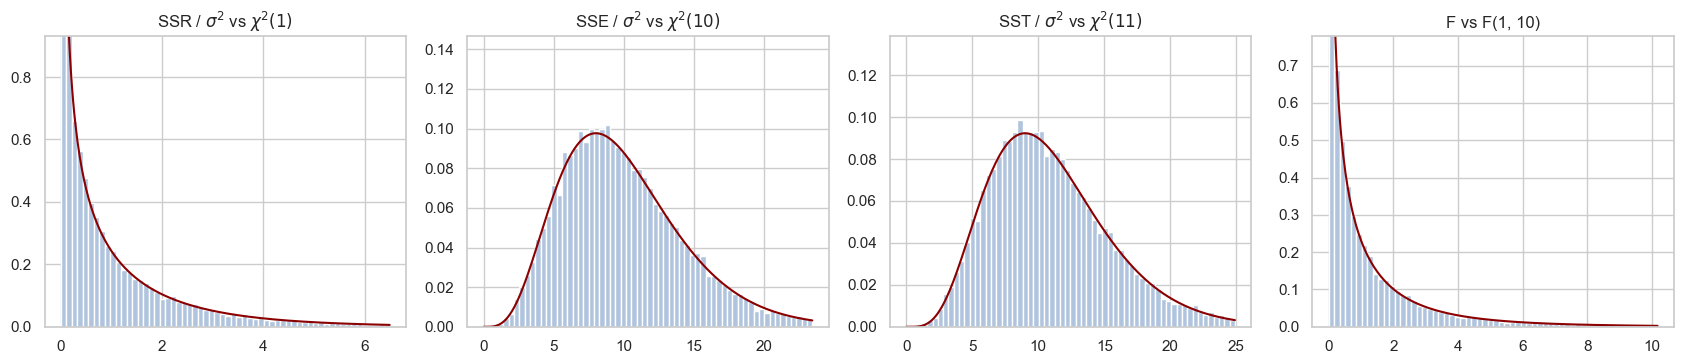

rejection rate of H0: beta1 = 0 at alpha = 0.05: 0.0475
correlation of SSR and SSE: 0.0033 (independent under normal errors)


In [13]:
# ================= Simulation settings =================
beta0, beta1, sigma = 46.0, 0.0, 4.3          # beta1 = 0: H0 holds
x_design = np.sort(rng.choice(x, size=12, replace=False))
n_sim = 20_000
# =======================================================

m_d = len(x_design)
xc = x_design - x_design.mean()
Sxx_d = np.sum(xc ** 2)
Y = beta0 + beta1 * x_design + sigma * rng.standard_normal((n_sim, m_d))
b1_sim = (Y @ xc) / Sxx_d
SSR_sim = b1_sim ** 2 * Sxx_d
SST_sim = np.sum((Y - Y.mean(axis=1, keepdims=True)) ** 2, axis=1)
SSE_sim = SST_sim - SSR_sim
F_sim = SSR_sim / (SSE_sim / (m_d - 2))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
panels = [(SSR_sim / sigma ** 2, stats.chi2(1), 'SSR / $\\sigma^2$ vs $\\chi^2(1)$'),
          (SSE_sim / sigma ** 2, stats.chi2(m_d - 2), f'SSE / $\\sigma^2$ vs $\\chi^2({m_d - 2})$'),
          (SST_sim / sigma ** 2, stats.chi2(m_d - 1), f'SST / $\\sigma^2$ vs $\\chi^2({m_d - 1})$'),
          (F_sim, stats.f(1, m_d - 2), f'F vs F(1, {m_d - 2})')]
for ax, (vals, dist, title) in zip(axes, panels):
    upper = np.quantile(vals, 0.99)
    ax.hist(vals[vals < upper], bins=60, density=True, color='lightsteelblue')
    grid_d = np.linspace(1e-3, upper, 300)
    ax.plot(grid_d, dist.pdf(grid_d), color='darkred')
    ax.set_ylim(0, 1.5 * np.max(dist.pdf(grid_d[grid_d > 0.3 * dist.mean()])))
    ax.set_title(title)
plt.tight_layout()
plt.show()

F_crit_d = stats.f.ppf(0.95, 1, m_d - 2)
print(f'rejection rate of H0: beta1 = 0 at alpha = 0.05: {np.mean(F_sim > F_crit_d):.4f}')
print(f'correlation of SSR and SSE: {np.corrcoef(SSR_sim, SSE_sim)[0, 1]:.4f} (independent under normal errors)')

## 8. $R^2$ needs care
Remark 2.13 warned against judging a model by $R^2$ alone:
- a small $R^2$ does not mean that the regression is not significant; there may simply be a lot of unexplained random variability;
- a large $R^2$ can be caused by a large spread of the $x$ values (large $S_{xx}$), and models with a steep slope tend to have a larger $R^2$ than models with a flat one.

The reason is visible from the expected sums of squares. With $\mathrm{E}\,\widehat{\beta}_1^2 = \sigma^2/S_{xx} + \beta_1^2$ we get $\mathrm{E}\,\mathrm{SSR} = \sigma^2 + \beta_1^2 S_{xx}$ and $\mathrm{E}\,\mathrm{SST} = (n-1)\sigma^2 + \beta_1^2 S_{xx}$, so roughly

$$R^2 \approx \frac{\sigma^2 + \beta_1^2 S_{xx}}{(n-1)\sigma^2 + \beta_1^2 S_{xx}} \approx \frac{\beta_1^2 s_x^2}{\beta_1^2 s_x^2 + \sigma^2}, \qquad s_x^2 = \frac{S_{xx}}{n-1},$$

an increasing function of the spread of $x$ and of $\beta_1^2$, while $\sigma^2$, the actual quality of the fit, stays the same.

We take one and the same "true" model for fuel efficiency and only change the range of weights in the design.

In [14]:
beta0, beta1, sigma = 46.2, -0.0076, 4.3       # close to the fit of mpg ~ weight
n_obs, n_rep = 100, 2000
rows = []
for lo, hi in [(2700, 3100), (2400, 3400), (2000, 4000), (1600, 5200)]:
    xd = np.linspace(lo, hi, n_obs)
    Sxx_d = np.sum((xd - xd.mean()) ** 2)
    Y = beta0 + beta1 * xd + sigma * rng.standard_normal((n_rep, n_obs))
    r2 = np.array([np.corrcoef(xd, yy)[0, 1] ** 2 for yy in Y])
    approx = (sigma ** 2 + beta1 ** 2 * Sxx_d) / ((n_obs - 1) * sigma ** 2 + beta1 ** 2 * Sxx_d)
    rows.append({'weights (lb)': f'{lo}-{hi}', 'S_xx': Sxx_d, 'mean R^2': r2.mean(),
                 'approximation': approx, 'SE(beta1_hat)': sigma / np.sqrt(Sxx_d)})
pd.DataFrame(rows)

,weights (lb),S_xx,mean R^2,approximation,SE(beta1_hat)
0,2700-3100,1.3603e+06,0.0505,0.0508,0.0037
1,2400-3400,8.5017e+06,0.2168,0.2195,0.0015
2,2000-4000,3.4007e+07,0.5210,0.5225,0.0007
3,1600-5200,1.1018e+08,0.7774,0.7789,0.0004


The model is identical in all four rows, the residual standard deviation is always $\sigma = 4.3$ mpg, yet $R^2$ ranges from almost nothing to more than 0.8. The same happens in the real data: restricting the cars to a narrow band of weights lowers $R^2$ a lot, while $s_n$ stays about the same. (The slope changes as well; that is a first hint that the relationship is not exactly linear, see Section 12.)

In [15]:
rows = []
for lo, hi in [(1600, 5200), (2500, 3500), (2800, 3200)]:
    sub = cars[(cars['weight'] >= lo) & (cars['weight'] <= hi)]
    fit = smf.ols('mpg ~ weight', data=sub).fit()
    rows.append({'weights (lb)': f'{lo}-{hi}', 'n': int(fit.nobs), 'beta1_hat * 1000': 1000 * fit.params['weight'],
                 's_n': np.sqrt(fit.scale), 'R^2': fit.rsquared, 'p-value (F)': fit.f_pvalue})
pd.DataFrame(rows)

,weights (lb),n,beta1_hat * 1000,s_n,R^2,p-value (F)
0,1600-5200,392,-7.6473,4.3327,0.6926,6.0153e-102
1,2500-3500,140,-9.3974,4.0454,0.3232,2.3455e-13
2,2800-3200,50,-10.6656,4.8858,0.0594,8.8126e-02


The opposite situation: a large sample with a weak but real effect. The test is highly significant, yet $R^2$ is small, because most of the variability of $y$ is noise that no line can explain. Both statements are correct; they answer different questions (is there a linear effect at all, versus how much of $y$ does it explain).

beta1_hat = 0.182,  p-value = 1.1e-14,  R^2 = 0.029


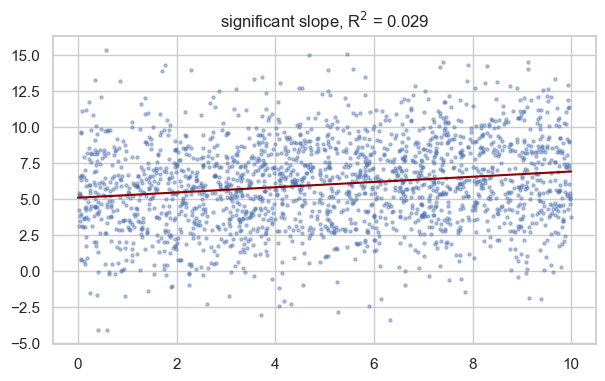

In [16]:
n_big = 2000
x_big = rng.uniform(0, 10, n_big)
y_big = 5 + 0.2 * x_big + rng.normal(0, 3, n_big)
fit_big = smf.ols('y ~ x', data=pd.DataFrame({'x': x_big, 'y': y_big})).fit()
print(f'beta1_hat = {fit_big.params["x"]:.3f},  p-value = {fit_big.f_pvalue:.1e},  R^2 = {fit_big.rsquared:.3f}')

plt.figure(figsize=(7, 4))
plt.scatter(x_big, y_big, s=5, alpha=0.4)
plt.plot([0, 10], fit_big.params['Intercept'] + fit_big.params['x'] * np.array([0, 10]), color='darkred')
plt.title(f'significant slope, R$^2$ = {fit_big.rsquared:.3f}')
plt.show()

Lecture 3 therefore listed several criteria of model quality: a large $R^2$, large $F$ or $|T_1|$, and a small $s_n^2$ relative to $\overline{y}$; more criteria will follow.

## 9. Correlation is not causation
Example 2.3 of Lecture 3: in England 1924–1937 the number of mental illness diagnoses per 100,000 inhabitants regressed on the number of radios gave $R^2 = 0.984$. The plausible explanation is a **hidden cause** (skrytá příčina): both quantities grew with time. The original data are not reproduced here; we simulate two series that both grow linearly in time and have nothing to do with each other.

diagnoses ~ radios: R^2 = 0.983, p-value = 6.4e-12
correlation after removing the time trend: -0.715 (R^2 = 0.511)


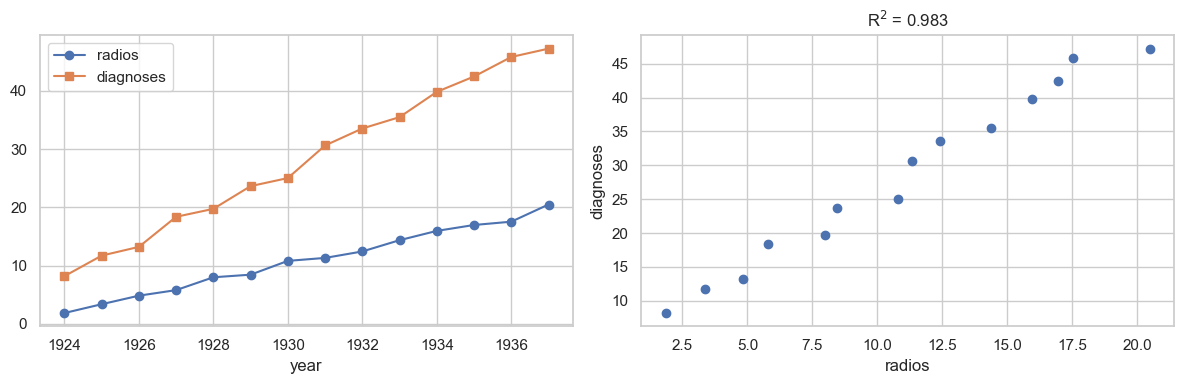

In [17]:
year = np.arange(1924, 1938)
radios = 1.4 * (year - 1924) + 1.5 + rng.normal(0, 0.4, len(year))        # millions of licences (illustrative)
diagnoses = 8 + 3.1 * (year - 1924) + rng.normal(0, 0.8, len(year))      # per 100,000 inhabitants (illustrative)
toy = pd.DataFrame({'year': year, 'radios': radios, 'diagnoses': diagnoses})

fit_toy = smf.ols('diagnoses ~ radios', data=toy).fit()
print(f'diagnoses ~ radios: R^2 = {fit_toy.rsquared:.3f}, p-value = {fit_toy.f_pvalue:.1e}')

# remove the common time trend from both series and correlate what is left
res_d = smf.ols('diagnoses ~ year', data=toy).fit().resid
res_r = smf.ols('radios ~ year', data=toy).fit().resid
r_detr = np.corrcoef(res_r, res_d)[0, 1]
print(f'correlation after removing the time trend: {r_detr:.3f} (R^2 = {r_detr ** 2:.3f})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(year, radios, 'o-', label='radios')
axes[0].plot(year, diagnoses, 's-', label='diagnoses')
axes[0].set_xlabel('year')
axes[0].legend()
axes[1].scatter(radios, diagnoses)
axes[1].set_xlabel('radios')
axes[1].set_ylabel('diagnoses')
axes[1].set_title(f'R$^2$ = {fit_toy.rsquared:.3f}')
plt.tight_layout()
plt.show()

With only 14 years a single sample can show almost any correlation of the detrended series by chance. We repeat the experiment many times: the raw $R^2$ is always close to one, while the correlation that remains after removing the trend scatters around zero, exactly as for two independent samples of this size.

In [18]:
t_c = year - year.mean()
raw_r2, detr_r = [], []
for _ in range(5000):
    rad = 1.4 * (year - 1924) + 1.5 + rng.normal(0, 0.4, len(year))
    dia = 8 + 3.1 * (year - 1924) + rng.normal(0, 0.8, len(year))
    raw_r2.append(np.corrcoef(rad, dia)[0, 1] ** 2)
    res_rad = rad - rad.mean() - (rad @ t_c) / (t_c @ t_c) * t_c       # residuals of rad ~ year
    res_dia = dia - dia.mean() - (dia @ t_c) / (t_c @ t_c) * t_c       # residuals of dia ~ year
    detr_r.append(np.corrcoef(res_rad, res_dia)[0, 1])
raw_r2, detr_r = np.array(raw_r2), np.array(detr_r)
print(f'raw R^2 of diagnoses ~ radios: median {np.median(raw_r2):.3f}, 5% quantile {np.quantile(raw_r2, 0.05):.3f}')
print(f'correlation after detrending : mean {detr_r.mean():.3f}, middle 90% of the values '
      f'({np.quantile(detr_r, 0.05):.2f}, {np.quantile(detr_r, 0.95):.2f})')

raw R^2 of diagnoses ~ radios: median 0.993, 5% quantile 0.986
correlation after detrending : mean 0.001, middle 90% of the values (-0.48, 0.48)


The strong association disappears once the common trend is taken into account. Remark 2.14 lists four situations behind a strong correlation: a **causal link** (příčinná spojitost) in one of the two directions, a **hidden cause** $z$ driving both $x$ and $y$ (as here, with $z$ = time), a **confounding factor** (zavádějící faktor) $z$ that influences $y$ together with $x$, and a **coincidence** (shoda okolností). Regression measures association; a causal interpretation needs an argument from the design of the study (for example a randomised experiment), not from $R^2$. Adjusting for a third variable, as we did with `year`, is exactly what multiple regression will do.

## 10. Regression through the origin
Lecture 4 considered the model $Y_i = \beta_1 x_i + e_i$. Least squares gives

$$\widehat{\beta}_1 = \frac{\sum_i x_i y_i}{\sum_i x_i^2}, \qquad \mathrm{Var}(\widehat{\beta}_1) = \frac{\sigma^2}{\sum_i x_i^2}, \qquad s_n^2 = \frac{\mathrm{SSE}}{n-1},$$

with $n-1$ degrees of freedom, because only one parameter is estimated; tests and intervals use $t(n-1)$. The decomposition around $\overline{y}$ no longer holds (there is no normal equation $\sum_i \widehat{e}_i = 0$). Instead, Theorem 2.6 gives the decomposition around zero,

$$\sum_i y_i^2 = \sum_i \widehat{y}_i^2 + \sum_i (y_i - \widehat{y}_i)^2,$$

which leads to the uncentred $R^2 = \sum_i \widehat{y}_i^2 / \sum_i y_i^2$ and to the ANOVA table with df $1$, $n-1$, $n$.

**Data of Example 2.4.** Birth weight (g) and gestational age (weeks) of 12 boys and 12 girls; the data set appears in A. J. Dobson's textbook *An Introduction to Generalized Linear Models* and reproduces the numbers on the slides exactly.

In [19]:
birth = pd.DataFrame({
    'Age': [40, 38, 40, 35, 36, 37, 41, 40, 37, 38, 40, 38,
            40, 36, 40, 38, 42, 39, 40, 37, 36, 38, 39, 40],
    'Weight': [2968, 2795, 3163, 2925, 2625, 2847, 3292, 3473, 2628, 3176, 3421, 2975,
               3317, 2729, 2935, 2754, 3210, 2817, 3126, 2539, 2412, 2991, 2875, 3231],
    'sex': ['boy'] * 12 + ['girl'] * 12})

mod = smf.ols('Weight ~ Age', data=birth).fit()          # R: lm(Weight ~ Age)
mod0 = smf.ols('Weight ~ Age - 1', data=birth).fit()     # R: lm(Weight ~ Age - 1)

xa = birth['Age'].to_numpy(dtype=float)
ya = birth['Weight'].to_numpy(dtype=float)
na = len(xa)
b1_0 = np.sum(xa * ya) / np.sum(xa ** 2)
yhat0 = b1_0 * xa
SSE0 = np.sum((ya - yhat0) ** 2)
s0 = np.sqrt(SSE0 / (na - 1))
se_b1_0 = s0 / np.sqrt(np.sum(xa ** 2))

pd.DataFrame({
    'with intercept': [mod.params['Age'], mod.bse['Age'], np.sqrt(mod.scale), mod.df_resid, mod.rsquared, mod.fvalue],
    'through origin (manual)': [b1_0, se_b1_0, s0, na - 1, np.sum(yhat0 ** 2) / np.sum(ya ** 2), np.nan],
    'through origin (statsmodels)': [mod0.params['Age'], mod0.bse['Age'], np.sqrt(mod0.scale), mod0.df_resid,
                                     mod0.rsquared, mod0.fvalue],
    'slides': ['115.5 / 77.081', '22.1 / 1.063', '192.6 / 200.9', '22 / 23', '0.554 / 0.9956', '27.33 / 5258'],
}, index=['beta1_hat', 'SE(beta1_hat)', 's_n', 'residual df', 'R^2', 'F'])

,with intercept,through origin (manual),through origin (statsmodels),slides
beta1_hat,115.5283,77.0808,77.0808,115.5 / 77.081
SE(beta1_hat),22.0987,1.0630,1.0630,22.1 / 1.063
s_n,192.5988,200.9321,200.9321,192.6 / 200.9
residual df,22.0000,23.0000,23.0000,22 / 23
R^2,0.5540,0.9956,0.9956,0.554 / 0.9956
F,27.3303,NaN,5257.6372,27.33 / 5258


In [20]:
print('Theorem 2.6: sum y^2 = sum yhat^2 + sum e^2')
print(f'  {np.sum(ya ** 2):.0f} = {np.sum(yhat0 ** 2):.0f} + {SSE0:.0f}  (difference {np.sum(ya ** 2) - np.sum(yhat0 ** 2) - SSE0:.1e})')
print(f'sum of residuals in the model through the origin: {np.sum(ya - yhat0):.1f} (not zero)')

SSR0 = np.sum(yhat0 ** 2)
display(pd.DataFrame({'df': [1, na - 1, na], 'SS': [SSR0, SSE0, np.sum(ya ** 2)],
                      'MS': [SSR0, SSE0 / (na - 1), np.nan], 'F': [SSR0 / s0 ** 2, np.nan, np.nan]},
                     index=['Regression', 'Residual', 'Total']))
print(sm.stats.anova_lm(mod0))              # R: anova(mod.bez)

Theorem 2.6: sum y^2 = sum yhat^2 + sum e^2
  213198964 = 212270368 + 928596  (difference -6.1e-08)
sum of residuals in the model through the origin: -75.8 (not zero)


,df,SS,MS,F
Regression,1,2.1227e+08,2.1227e+08,5257.6372
Residual,23,9.2860e+05,4.0374e+04,NaN
Total,24,2.1320e+08,NaN,NaN


            df      sum_sq     mean_sq          F      PR(>F)
Age        1.0  2.1227e+08  2.1227e+08  5257.6372  1.1647e-28
Residual  23.0  9.2860e+05  4.0374e+04        NaN         NaN


The uncentred $R^2 = 0.9956$ of the model through the origin looks far better than $R^2 = 0.554$ of the model with intercept, although its residual sum of squares is *larger* ($s_n = 200.9$ against $192.6$). The two numbers are not comparable: the first measures variability around zero, $\sum_i y_i^2$, the second around the mean, $\sum_i (y_i - \overline{y})^2$, which is much smaller (Remark 2.17). This is also why `statsmodels` and R report a different kind of `R-squared` as soon as the intercept is dropped.

Lecture 4 mentioned $R^2 = \rho^2(\mathbf{y}, \widehat{\mathbf{y}})$ as one possible definition for both models; on the slide it equals $0.554$ for the model through the origin. Note that in simple regression through the origin $\widehat{y}_i = \widehat{\beta}_1 x_i$ is proportional to $x_i$, so $\rho^2(\mathbf{y}, \widehat{\mathbf{y}}) = \rho^2(\mathbf{x}, \mathbf{y})$ is the same number as the $R^2$ of the model with intercept and cannot distinguish the two lines. The fair comparison is through $s_n^2$, the other option on the slide.

rho^2(y, yhat) through the origin: 0.5540268
rho^2(x, y)                      : 0.5540268
R^2 with intercept               : 0.5540268


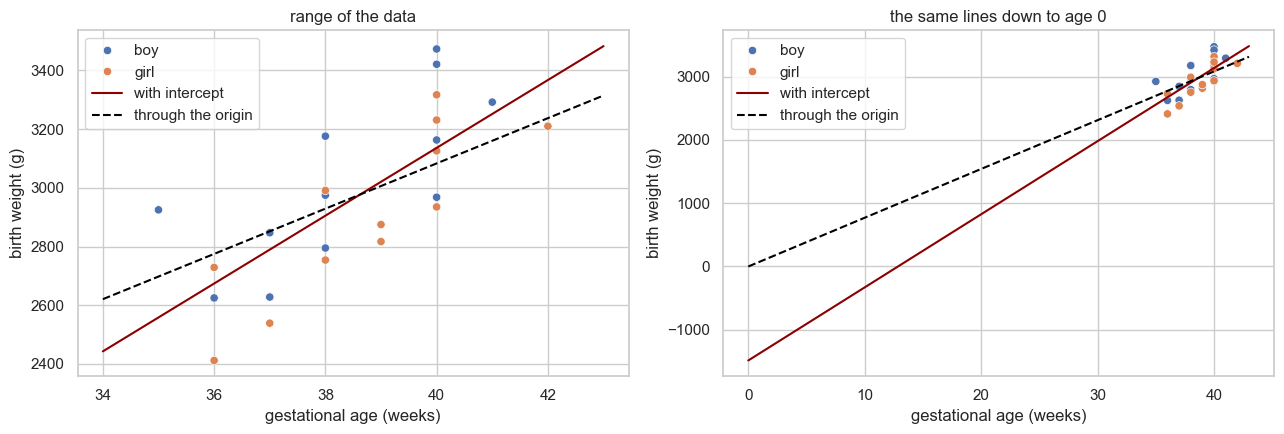

In [21]:
print(f'rho^2(y, yhat) through the origin: {np.corrcoef(ya, yhat0)[0, 1] ** 2:.7f}')
print(f'rho^2(x, y)                      : {np.corrcoef(xa, ya)[0, 1] ** 2:.7f}')
print(f'R^2 with intercept               : {mod.rsquared:.7f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (lo, hi) in zip(axes, [(34, 43), (0, 43)]):
    sns.scatterplot(data=birth, x='Age', y='Weight', hue='sex', ax=ax)
    ga = np.linspace(lo, hi, 100)
    ax.plot(ga, mod.params['Intercept'] + mod.params['Age'] * ga, color='darkred', label='with intercept')
    ax.plot(ga, mod0.params['Age'] * ga, color='black', ls='--', label='through the origin')
    ax.set_xlabel('gestational age (weeks)')
    ax.set_ylabel('birth weight (g)')
    ax.legend()
axes[0].set_title('range of the data')
axes[1].set_title('the same lines down to age 0')
plt.tight_layout()
plt.show()

A baby of age zero weighs nothing, so $\mathrm{E}\,Y_0 = 0$ at $x_0 = 0$ is true. Still the model through the origin is the worse one here: the data cover 35 to 42 weeks only, and nothing guarantees that the growth is linear all the way from conception. Forcing the line through the origin rotates it and biases the slope (77 g per week instead of 116 g per week). This is the warning of Remark 2.15: put $\beta_0 = 0$ a priori only when the model is known to be linear near zero.

## 11. Prediction: confidence interval for $\mathrm{E}\,Y_0$ and prediction interval for $Y_0$
For a new value $x_0$ both kinds of prediction use the same point estimate $\widehat{Y}_0 = \widehat{\beta}_0 + \widehat{\beta}_1 x_0$, but they answer different questions (Lecture 4):

1. **Confidence interval** for the mean response $\mu_0 = \mathrm{E}\,Y_0 = \beta_0 + \beta_1 x_0$, a parameter:
$$\widehat{Y}_0 \pm t_{1-\alpha/2}(n-2)\, \widehat{\sigma}(\widehat{Y}_0), \qquad \widehat{\sigma}^2(\widehat{Y}_0) = s_n^2\left[\frac{1}{n} + \frac{(x_0 - \overline{x})^2}{S_{xx}}\right];$$
$\widehat{\sigma}(\widehat{Y}_0)$ is the **standard error of prediction** at $x_0$ (standardní chyba predikce).
2. **Prediction interval** for a new observation $Y_0$, a random variable, so it is not a confidence interval:
$$\widehat{Y}_0 \pm t_{1-\alpha/2}(n-2)\, s_p, \qquad s_p = s_n\sqrt{1 + \frac{1}{n} + \frac{(x_0 - \overline{x})^2}{S_{xx}}}.$$

The extra $1$ under the root is the variance of the new error $e_0$; it does not disappear however large $n$ is.

In [22]:
x0 = np.array([1800.0, 3000.0, 4500.0, 6000.0])        # 6000 lb lies outside the data (max about 5140 lb)
t_q = stats.t.ppf(0.975, df=n - 2)
y0 = beta0_hat + beta1_hat * x0
se_mean = s_n * np.sqrt(1 / n + (x0 - x_bar) ** 2 / S_xx)
s_p = s_n * np.sqrt(1 + 1 / n + (x0 - x_bar) ** 2 / S_xx)

manual = pd.DataFrame({'x0': x0, 'y0_hat': y0,
                       'CI lower': y0 - t_q * se_mean, 'CI upper': y0 + t_q * se_mean,
                       'PI lower': y0 - t_q * s_p, 'PI upper': y0 + t_q * s_p})
display(manual)

# R: predict(mod, newdata, interval = "confidence") and interval = "prediction"
pred = model.get_prediction(pd.DataFrame({'weight': x0})).summary_frame(alpha=0.05)
pred

,x0,y0_hat,CI lower,CI upper,PI lower,PI upper
0,1800.0,32.4513,31.7152,33.1874,23.9012,41.0014
1,3000.0,23.2745,22.8441,23.7049,14.7452,31.8038
2,4500.0,11.8035,10.9196,12.6874,3.2394,20.3676
3,6000.0,0.3325,-1.2597,1.9246,-8.3334,8.9984


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,32.4513,0.3744,31.7152,33.1874,23.9012,41.0014
1,23.2745,0.2189,22.8441,23.7049,14.7452,31.8038
2,11.8035,0.4496,10.9196,12.6874,3.2394,20.3676
3,0.3325,0.8098,-1.2597,1.9246,-8.3334,8.9984


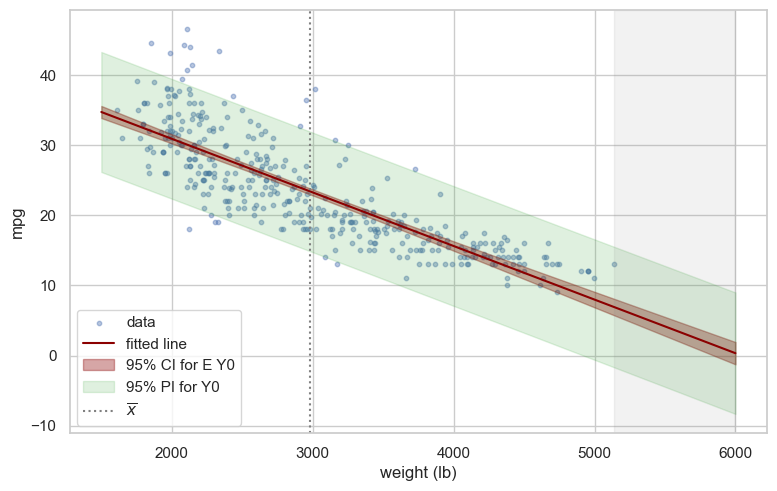

share of the 392 cars inside their 95% prediction interval: 0.944


In [23]:
grid = np.linspace(1500, 6000, 200)
band = model.get_prediction(pd.DataFrame({'weight': grid})).summary_frame(alpha=0.05)

plt.figure(figsize=(9, 5.5))
plt.scatter(x, y, s=10, alpha=0.4, label='data')
plt.plot(grid, band['mean'], color='darkred', label='fitted line')
plt.fill_between(grid, band['mean_ci_lower'], band['mean_ci_upper'], color='darkred', alpha=0.35,
                 label='95% CI for E Y0')
plt.fill_between(grid, band['obs_ci_lower'], band['obs_ci_upper'], color='tab:green', alpha=0.15,
                 label='95% PI for Y0')
plt.axvline(x_bar, color='gray', ls=':', label='$\\overline{x}$')
plt.axvspan(x.max(), 6000, color='gray', alpha=0.1)
plt.xlabel('weight (lb)')
plt.ylabel('mpg')
plt.legend()
plt.show()

inside = (y >= model.get_prediction().summary_frame()['obs_ci_lower']) & \
         (y <= model.get_prediction().summary_frame()['obs_ci_upper'])
print(f'share of the 392 cars inside their 95% prediction interval: {inside.mean():.3f}')

Both bands are narrowest at $x_0 = \overline{x}$ and widen with $|x_0 - \overline{x}|$ (Remark 2.18). The confidence band is narrow because 392 cars determine the line well; the prediction band stays wide, since an individual car scatters around the line with standard deviation $\sigma \approx s_n$. The precision of prediction grows with $n$ and with $S_{xx}$ and decreases with the distance from $\overline{x}$ (Remark 2.19). In the shaded region on the right, beyond the heaviest car, the intervals are formally available, but they rely on the assumption that the line continues outside the data, which the data cannot check.

Remark 2.20: the confidence interval for $\mathrm{E}\,Y_0$ is approximately valid for large $n$ also with non-normal errors (the estimates are asymptotically normal), the prediction interval for $Y_0$ relies on normality of the errors for any $n$.

**Example 2.5 (Clark County population).** The population of Clark County (Nevada) 1920–1980 by decades, $x = 0, \dots, 6$; the task is to predict 1990 ($x_0 = 7$). The true 1990 value was 768,203. We reproduce both models from the slides.

In [24]:
clark = pd.DataFrame({'x': np.arange(7), 'year': np.arange(1920, 1990, 10),
                      'pop': [4859, 8539, 16414, 48589, 127016, 273288, 463087]})
lin = smf.ols('pop ~ x', data=clark).fit()
logm = smf.ols('np.log(pop) ~ x', data=clark).fit()
new = pd.DataFrame({'x': [7]})

p_lin = lin.get_prediction(new).summary_frame(alpha=0.05)
p_log = logm.get_prediction(new).summary_frame(alpha=0.05)
cols = ['mean', 'mean_ci_lower', 'mean_ci_upper', 'obs_ci_lower', 'obs_ci_upper']
print(f'linear model: beta0 = {lin.params["Intercept"]:.0f}, beta1 = {lin.params["x"]:.0f}, '
      f'R^2 = {lin.rsquared:.2f}, F = {lin.fvalue:.2f}')
print(f'log model   : beta0 = {logm.params["Intercept"]:.3f}, beta1 = {logm.params["x"]:.3f}, '
      f'R^2 = {logm.rsquared:.3f}, F = {logm.fvalue:.1f}')
pd.DataFrame([p_lin[cols].iloc[0], p_log[cols].iloc[0], np.exp(p_log[cols].iloc[0])],
             index=['linear model', 'log model, log scale', 'log model, back-transformed']).round(3)

linear model: beta0 = -81328, beta1 = 71957, R^2 = 0.80, F = 19.96
log model   : beta0 = 8.338, beta1 = 0.809, R^2 = 0.991, F = 550.9


,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
linear model,4.2237e+05,237233.733,6.0750e+05,135559.227,7.0918e+05
"log model, log scale",1.4000e+01,13.604,1.4397e+01,13.387,1.4614e+01
"log model, back-transformed",1.2032e+06,809576.112,1.7881e+06,651268.635,2.2227e+06


The straight line is clearly wrong (negative fitted population in 1920, $R^2 = 0.80$ despite that) and its prediction interval misses the true value 768,203. The log model fits much better, and its back-transformed prediction interval $(651\,269,\ 2\,222\,733)$ contains the true value, but the point prediction of 1.2 million overshoots by more than 50 %: the growth slowed down after 1980. Two remarks for the back-transformation:
- the interval for $Y_0$ transforms correctly, because $\exp$ is increasing: $P(a < \log Y_0 < b) = P(e^a < Y_0 < e^b)$;
- $\exp$ of the estimated mean of $\log Y_0$ estimates the *median* of $Y_0$, not its mean (for log-normal $Y_0$ the mean is larger). Transformations will get a lecture of their own.

## 12. Model adequacy: residuals
All intervals and tests so far assumed that the model is linear and, for exact distributions, that the errors are normal. Lecture 4 listed three basic checks: look at the scatter plot, look at the test statistics critically (a large $R^2$ with a significant $t$ does not prove linearity), and analyse the **residuals**.

Theorem 2.7 describes the residuals of model $(\ast)$:
1. $\mathrm{E}\,\widehat{e}_i = 0$,
2. $\mathrm{Var}(\widehat{e}_i) = \sigma^2\left[1 - \left(\frac{1}{n} + \frac{(x_i - \overline{x})^2}{S_{xx}}\right)\right]$, smaller than $\sigma^2$ and smallest for $x_i$ far from $\overline{x}$,
3. $\mathrm{Cov}(\widehat{e}_i, \widehat{e}_j) = -\sigma^2\left[\frac{1}{n} + \frac{(\overline{x} - x_i)(\overline{x} - x_j)}{S_{xx}}\right]$, so the residuals are correlated even when the errors are not,
4. $\mathrm{Cov}(\widehat{e}_i, \widehat{Y}_i) = 0$,
5. for i.i.d. normal errors $\widehat{Z}_i = \widehat{e}_i / \sigma_{\widehat{e}_i} \sim N(0, 1)$.

We check points 2 to 4 by simulation on a small design with one point far from the others.

In [25]:
x_small = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 20], dtype=float)
m_s, sigma_s = len(x_small), 1.0
lev = 1 / m_s + (x_small - x_small.mean()) ** 2 / np.sum((x_small - x_small.mean()) ** 2)

Y = 1 + 0.5 * x_small + sigma_s * rng.standard_normal((50_000, m_s))
X_s = sm.add_constant(x_small)
B = np.linalg.lstsq(X_s, Y.T, rcond=None)[0]          # all 50,000 fits at once
Yhat = (X_s @ B).T
E = Y - Yhat

display(pd.DataFrame({'x_i': x_small,
                      'Var(e_i) theory': sigma_s ** 2 * (1 - lev),
                      'Var(e_i) simulated': E.var(axis=0),
                      'Cov(e_i, Yhat_i) simulated': [np.cov(E[:, i], Yhat[:, i])[0, 1] for i in range(m_s)]}).round(4))
i, j = 0, 1
cov_theory = -sigma_s ** 2 * (1 / m_s + (x_small.mean() - x_small[i]) * (x_small.mean() - x_small[j]) /
                              np.sum((x_small - x_small.mean()) ** 2))
print(f'Cov(e_1, e_2): theory {cov_theory:.4f}, simulated {np.cov(E[:, i], E[:, j])[0, 1]:.4f}')

,x_i,Var(e_i) theory,Var(e_i) simulated,"Cov(e_i, Yhat_i) simulated"
0,1.0,0.7848,0.7858,0.0026
1,2.0,0.8229,0.8217,-0.0004
2,3.0,0.8533,0.8570,-0.0007
3,4.0,0.8762,0.8744,-0.0013
4,5.0,0.8914,0.8970,0.0015
5,6.0,0.8990,0.8934,-0.0002
6,7.0,0.8990,0.9057,0.0002
7,8.0,0.8914,0.8882,-0.0021
8,9.0,0.8762,0.8677,0.0003
9,20.0,0.2057,0.2055,0.0000


Cov(e_1, e_2): theory -0.1943, simulated -0.1908


The isolated point $x = 20$ has a residual variance of only about $0.2\,\sigma^2$: the line is pulled towards it, so its residual is small even when its error is not. The quantity $\frac{1}{n} + \frac{(x_i - \overline{x})^2}{S_{xx}}$ measures how strongly the point $i$ pulls the line; Lecture 5 will introduce it as the diagonal element $h_{ii}$ of the hat matrix $\mathbf{H}$ (Exercise 04).

To compare residuals with each other we standardise them. Replacing $\sigma$ by $s_n$ gives the **studentized residuals** (studentizovaná rezidua; also called *internally studentized* or *standardized residuals*, R: `rstandard`), Remark 2.21:

$$\widehat{r}_i = \frac{\widehat{e}_i}{s_n\sqrt{1 - \left(\frac{1}{n} + \frac{(x_i - \overline{x})^2}{S_{xx}}\right)}},$$

which for large $n$ should behave like a sample from $N(0, 1)$ if the model holds. (PRESS residuals, based on leaving the $i$-th observation out, and the other variants will come later.)

In [26]:
lev_cars = 1 / n + (x - x_bar) ** 2 / S_xx
r_manual = e_hat / (s_n * np.sqrt(1 - lev_cars))
r_sm = model.get_influence().resid_studentized_internal      # R: rstandard(mod)
print(f'max |manual - statsmodels| = {np.max(np.abs(r_manual - r_sm)):.1e}')
print(f'share of |r_i| > 2: {np.mean(np.abs(r_manual) > 2):.3f},  > 3: {np.mean(np.abs(r_manual) > 3):.3f}')

max |manual - statsmodels| = 7.1e-15
share of |r_i| > 2: 0.048,  > 3: 0.013


Remark 2.22 listed the basic **residual plots** (grafy reziduí): a histogram, a **Q-Q plot** of the studentized residuals against the normal quantiles $\Phi^{-1}\big((i - \frac12)/n\big)$, the residuals against the regressor $x$, against the fitted values $\widehat{y}$, and against the order of the observations. If the model holds, the last three plots show a structureless horizontal band with most points within $(-3, 3)$.

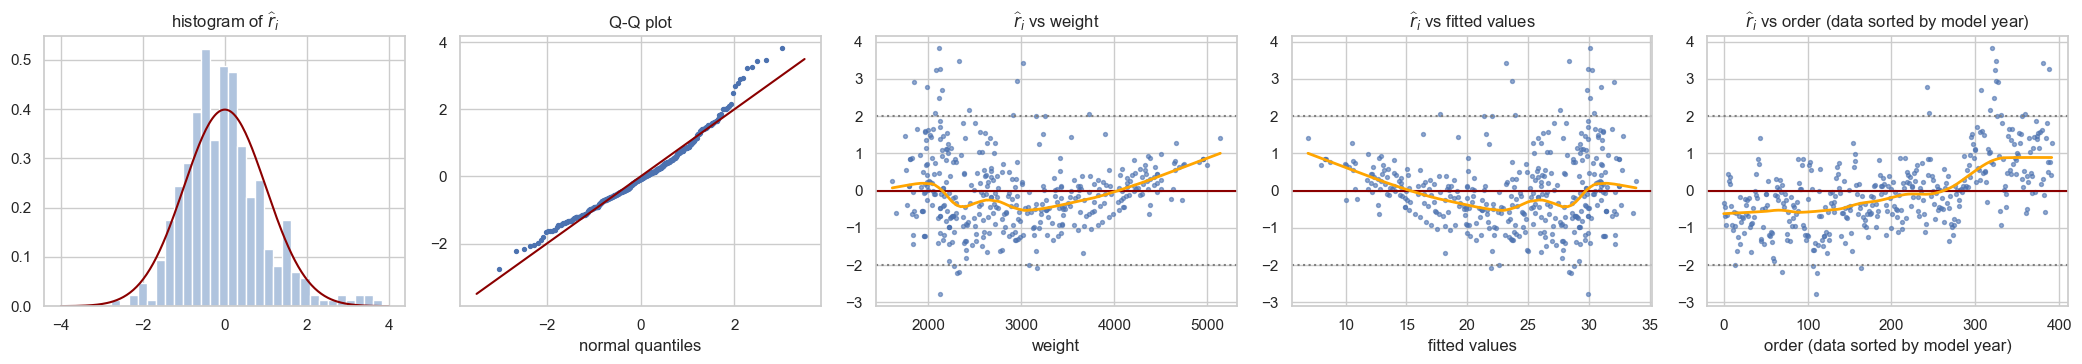

In [27]:
def residual_plots(fit, xvals, xname, order_name='observation order'):
    r = fit.get_influence().resid_studentized_internal
    m = len(r)
    fig, axes = plt.subplots(1, 5, figsize=(21, 3.8))
    axes[0].hist(r, bins=30, density=True, color='lightsteelblue')
    g = np.linspace(-4, 4, 200)
    axes[0].plot(g, stats.norm.pdf(g), color='darkred')
    axes[0].set_title('histogram of $\\widehat{r}_i$')
    q = stats.norm.ppf((np.arange(1, m + 1) - 0.5) / m)
    axes[1].scatter(q, np.sort(r), s=8)
    axes[1].plot([-3.5, 3.5], [-3.5, 3.5], color='darkred')
    axes[1].set_title('Q-Q plot')
    axes[1].set_xlabel('normal quantiles')
    for ax, (vals, lab) in zip(axes[2:], [(xvals, xname), (fit.fittedvalues, 'fitted values'),
                                          (np.arange(m), order_name)]):
        ax.scatter(vals, r, s=8, alpha=0.6)
        ax.axhline(0, color='darkred')
        for h in (-2, 2):
            ax.axhline(h, color='gray', ls=':')
        smooth = sm.nonparametric.lowess(r, vals, frac=0.3)
        ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2)
        ax.set_xlabel(lab)
        ax.set_title(f'$\\widehat{{r}}_i$ vs {lab}')
    plt.tight_layout()
    plt.show()


residual_plots(model, x, 'weight', 'order (data sorted by model year)')

The orange curve is a local smoother added to guide the eye. Reading the plots for `mpg ~ weight`:
- residuals against weight (and against fitted values, the same picture mirrored) form a **U-shape**: the relationship is curved, the straight line overestimates efficiency of medium cars and underestimates it for light and heavy cars;
- the spread is larger for light cars (large fitted values): the variance is not constant;
- the Q-Q plot bends upwards in the right tail, a consequence of the two previous points;
- the data are ordered by model year and the residuals drift upwards with it: newer cars are more efficient than their weight predicts. A variable missing from the model shows up in the residuals.

For comparison the model of Section 2, L/100 km on kW, where the reciprocal scale straightened the relationship:

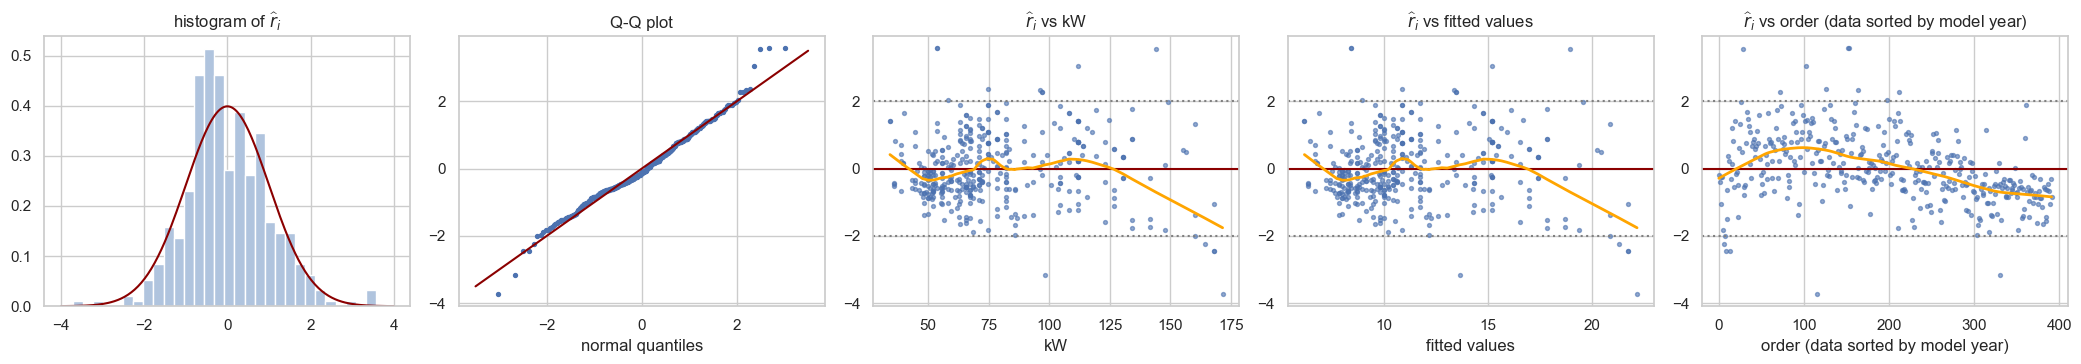

In [28]:
residual_plots(fuel, xk, 'kW', 'order (data sorted by model year)')

In the bulk of the data the U-shape is gone and the band is roughly horizontal; only for the few most powerful cars (above about 130 kW) does the smoother bend down. The pattern in model year remains, now with the opposite sign because the response measures consumption: newer cars consume less than their power predicts. Remedies (transformations, weighted least squares, additional regressors) will follow in later lectures; at this stage it is enough to recognise the patterns.

## 13. Individual work: advertising and sales
The `Advert.csv` data contain, for 200 markets, the advertising budget spent on `TV`, `radio` and `newspaper` (thousands of dollars) and the product `sales` (thousands of units). Use simple regressions only. Write a short conclusion after each step.

1. Fit the three simple regressions `sales ~ TV`, `sales ~ radio`, `sales ~ newspaper`. For each, give the ANOVA table, $R^2$, $F$ and its $p$-value in one summary table. Which medium alone explains the most of the variability of sales?
2. `newspaper` is significant at 5 %, but what is its $R^2$? Explain how both can be true (Remark 2.13).
3. For `sales ~ TV`, verify numerically $R^2 = \rho^2(\mathbf{x}, \mathbf{y})$ and $F = T_1^2$.
4. Compute by hand and with `get_prediction` the 95 % confidence interval for mean sales and the 95 % prediction interval for sales in one market, for TV budgets 50, 150 and 300 thousand dollars. Which of the two intervals matters for a manager planning one campaign in one market? Is any of the budgets an extrapolation?
5. Draw the residual plots for `sales ~ TV`. Which assumption of the model is questionable, and what does that mean for the prediction intervals from step 4?
6. Would a model through the origin make sense for `sales ~ TV`? Fit it, compare $s_n$ with the model with intercept, and explain why comparing the two `R-squared` values would be misleading.
7. Markets with a large TV budget have higher sales. Does that prove that TV advertising causes sales? Name a possible hidden cause.

In [29]:
url_adv = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/Advert.csv'
advert = pd.read_csv(url_adv, index_col=0)
advert.head()

,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [30]:
# your solution


## 14. What to remember
- $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$ for a model with intercept; $R^2 = \mathrm{SSR}/\mathrm{SST} = \rho^2(\mathbf{x}, \mathbf{y})$ is the share of the variability explained by the line.
- $F = (n-2)R^2/(1-R^2) = \mathrm{SSR}/s_n^2 = T_1^2 \sim F(1, n-2)$ under $H_0: \beta_1 = 0$; the ANOVA table (`anova_lm`, R: `anova`) arranges df, SS, MS and $F$.
- $R^2$ depends on the spread of $x$ and on the slope, not only on the quality of the fit; a significant model can have a small $R^2$; a large $R^2$ proves neither linearity nor causation.
- Through the origin: $\widehat{\beta}_1 = \sum x_i y_i / \sum x_i^2$, $n-1$ degrees of freedom, uncentred $R^2$ not comparable with the usual one; compare models by $s_n^2$, and drop the intercept only when linearity near zero is known.
- Confidence interval for $\mathrm{E}\,Y_0$ versus prediction interval for $Y_0$: same centre, the prediction interval has the extra $1$ under the root; both widen away from $\overline{x}$, extrapolation is risky.
- Residuals have unequal variances $\sigma^2(1 - h_{ii})$; studentized residuals $\widehat{r}_i$ and the residual plots reveal curvature, non-constant variance, non-normality and missing variables.